In [1]:
# Load data, prepare delta target

import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/kathmandu_features.csv")
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"])
df = df.sort_values("datetime_utc").reset_index(drop=True)

target_column = "target_pm25_next_1h"
feature_columns = [col for col in df.columns if col not in ["datetime_utc", target_column]]

current_pm25 = df["pm25"]
y_absolute = df[target_column]
y_delta = y_absolute - current_pm25

# Drop rows where the delta target is NaN 
valid_mask = ~y_delta.isna()
X = df.loc[valid_mask, feature_columns].reset_index(drop=True)
y_delta_valid = y_delta[valid_mask].reset_index(drop=True)
y_absolute_valid = y_absolute[valid_mask].reset_index(drop=True)
current_pm25_valid = current_pm25[valid_mask].reset_index(drop=True)
dates_valid = df.loc[valid_mask, "datetime_utc"].reset_index(drop=True)

print(f"Rows after dropping missing target: {len(X)} (from {len(df)})")
print(f"Features: {len(feature_columns)}")

# Hold-out: keeping the last period aside, used once at the end
test_start = pd.Timestamp("2026-08-01")
dev = (dates_valid < test_start).values

X_full, y_delta_full = X, y_delta_valid  

X_hold = X[~dev].reset_index(drop=True)
y_abs_hold = y_absolute_valid[~dev].reset_index(drop=True)
pm25_hold = current_pm25_valid[~dev].reset_index(drop=True)
dates_hold = dates_valid[~dev].reset_index(drop=True)

X = X[dev].reset_index(drop=True)
y_delta_valid = y_delta_valid[dev].reset_index(drop=True)
y_absolute_valid = y_absolute_valid[dev].reset_index(drop=True)
current_pm25_valid = current_pm25_valid[dev].reset_index(drop=True)
dates_valid = dates_valid[dev].reset_index(drop=True)

print(f"Development: {len(X)} rows, Hold-out: {len(X_hold)} rows "
      f"({dates_hold.min().date()} to {dates_hold.max().date()})")

Rows after dropping missing target: 8312 (from 8343)
Features: 32
Development: 6958 rows, Hold-out: 1354 rows (2026-08-01 to 2026-09-03)


In [2]:
# Define the search space and run RandomizedSearchCV

param_distributions = {
    "n_estimators": [50, 100, 150, 200, 300],
    "max_depth": [2, 3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 7],
    "reg_alpha": [0, 0.01, 0.1, 1],
    "reg_lambda": [0.5, 1, 1.5, 2],
}

tscv = TimeSeriesSplit(n_splits=5)

base_model = xgb.XGBRegressor(random_state=42, n_jobs=-1)

search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_distributions,
    n_iter=50,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

search.fit(X, y_delta_valid)

print("Best parameters found:")
print(search.best_params_)
print(f"\nBest CV RMSE (on delta target): {-search.best_score_:.3f}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best parameters found:
{'subsample': 0.6, 'reg_lambda': 1.5, 'reg_alpha': 0.1, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.6}

Best CV RMSE (on delta target): 14.451


In [3]:
# Evaluate the tuned model on the same folds, reconstructed to absolute PM2.5

tuned_results = []
tuned_predictions = []

best_params = search.best_params_

for fold_num, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_delta_train = y_delta_valid.iloc[train_idx]
    y_absolute_test = y_absolute_valid.iloc[test_idx]
    current_pm25_test = current_pm25_valid.iloc[test_idx]
    dates_test = dates_valid.iloc[test_idx]

    model = xgb.XGBRegressor(random_state=42, n_jobs=-1, **best_params)
    model.fit(X_train, y_delta_train)

    predicted_delta = model.predict(X_test)
    predicted_absolute = current_pm25_test.values + predicted_delta

    valid_mask_fold = ~np.isnan(predicted_absolute)

    rmse = np.sqrt(mean_squared_error(y_absolute_test[valid_mask_fold], predicted_absolute[valid_mask_fold]))
    mae = mean_absolute_error(y_absolute_test[valid_mask_fold], predicted_absolute[valid_mask_fold])
    r2 = r2_score(y_absolute_test[valid_mask_fold], predicted_absolute[valid_mask_fold])

    tuned_results.append({"fold": fold_num, "rmse_tuned": rmse, "mae_tuned": mae, "r2_tuned": r2})
    tuned_predictions.append({
        "fold": fold_num, "dates": dates_test[valid_mask_fold],
        "y_actual": y_absolute_test[valid_mask_fold], "y_pred": predicted_absolute[valid_mask_fold],
    })

    print(f"Fold {fold_num} ({dates_test.min().date()} to {dates_test.max().date()}): "
          f"RMSE={rmse:.2f} MAE={mae:.2f} R2={r2:.3f}")

tuned_df = pd.DataFrame(tuned_results)

Fold 1 (2025-12-19 to 2026-01-14): RMSE=18.48 MAE=12.75 R2=0.748
Fold 2 (2026-01-14 to 2026-03-20): RMSE=20.92 MAE=12.95 R2=0.768
Fold 3 (2026-03-20 to 2026-04-14): RMSE=13.59 MAE=8.37 R2=0.832
Fold 4 (2026-04-14 to 2026-06-22): RMSE=12.46 MAE=7.61 R2=0.920
Fold 5 (2026-06-22 to 2026-07-31): RMSE=7.03 MAE=4.53 R2=0.780


In [4]:
# Final, one-time evaluation on the hold-out (NOT USED FOR TUNING)

holdout_model = xgb.XGBRegressor(random_state=42, n_jobs=-1, **best_params)
holdout_model.fit(X, y_delta_valid)   # development data only
pred_hold = pm25_hold.values + holdout_model.predict(X_hold)

rmse_hold = np.sqrt(mean_squared_error(y_abs_hold, pred_hold))
mae_hold = mean_absolute_error(y_abs_hold, pred_hold)
r2_hold = r2_score(y_abs_hold, pred_hold)
rmse_hold_persist = np.sqrt(mean_squared_error(y_abs_hold, pm25_hold))
skill_hold = 1 - rmse_hold / rmse_hold_persist

print(f"Hold-out {dates_hold.min().date()} to {dates_hold.max().date()}")
print(f"Tuned XGBoost: RMSE={rmse_hold:.2f}  MAE={mae_hold:.2f}  R2={r2_hold:.3f}")
print(f"Persistence  : RMSE={rmse_hold_persist:.2f}")
print(f"Skill vs persistence: {skill_hold * 100:+.1f}%")

Hold-out 2026-08-01 to 2026-09-03
Tuned XGBoost: RMSE=6.56  MAE=4.27  R2=0.636
Persistence  : RMSE=7.05
Skill vs persistence: +6.9%


In [5]:
# Compare tuned model against the untuned XGBoost and persistence

# Persistence, recomputed on the same valid-row set
persist_results = []
for fold_num, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):
    y_absolute_test = y_absolute_valid.iloc[test_idx]
    current_pm25_test = current_pm25_valid.iloc[test_idx]
    valid_mask_p = ~current_pm25_test.isna()
    rmse_p = np.sqrt(mean_squared_error(y_absolute_test[valid_mask_p], current_pm25_test[valid_mask_p]))
    r2_p = r2_score(y_absolute_test[valid_mask_p], current_pm25_test[valid_mask_p])
    persist_results.append({"fold": fold_num, "rmse_persist": rmse_p, "r2_persist": r2_p})
persist_df = pd.DataFrame(persist_results)

# Untuned XGBoost for comparison
untuned_results = []
for fold_num, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_delta_train = y_delta_valid.iloc[train_idx]
    y_absolute_test = y_absolute_valid.iloc[test_idx]
    current_pm25_test = current_pm25_valid.iloc[test_idx]

    untuned_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42, n_jobs=-1,)
    untuned_model.fit(X_train, y_delta_train)
    pred_delta = untuned_model.predict(X_test)
    pred_absolute = current_pm25_test.values + pred_delta

    valid_mask_u = ~np.isnan(pred_absolute)
    rmse_u = np.sqrt(mean_squared_error(y_absolute_test[valid_mask_u], pred_absolute[valid_mask_u]))
    r2_u = r2_score(y_absolute_test[valid_mask_u], pred_absolute[valid_mask_u])
    untuned_results.append({"fold": fold_num, "rmse_untuned": rmse_u, "r2_untuned": r2_u})
untuned_df = pd.DataFrame(untuned_results)

final_comparison = tuned_df.merge(untuned_df, on="fold").merge(persist_df, on="fold")

print(final_comparison[["fold", "rmse_tuned", "rmse_untuned", "rmse_persist"]].to_string(index=False))
print()
print(final_comparison[["fold", "r2_tuned", "r2_untuned", "r2_persist"]].to_string(index=False))

print()
print("=== AVERAGES ===")
print(f"Tuned XGBoost   : RMSE={final_comparison['rmse_tuned'].mean():.2f}  R2={final_comparison['r2_tuned'].mean():.3f}")
print(f"Untuned XGBoost : RMSE={final_comparison['rmse_untuned'].mean():.2f}  R2={final_comparison['r2_untuned'].mean():.3f}")
print(f"Persistence     : RMSE={final_comparison['rmse_persist'].mean():.2f}  R2={final_comparison['r2_persist'].mean():.3f}")

improvement_vs_persist = (1 - final_comparison['rmse_tuned'].mean() / final_comparison['rmse_persist'].mean()) * 100
improvement_vs_untuned = (1 - final_comparison['rmse_tuned'].mean() / final_comparison['rmse_untuned'].mean()) * 100
print(f"\nTuned model improvement over persistence: {improvement_vs_persist:.1f}%")
print(f"Tuned model improvement over untuned XGBoost: {improvement_vs_untuned:.1f}%")

 fold  rmse_tuned  rmse_untuned  rmse_persist
    1   18.477709     18.290023     23.721757
    2   20.920919     20.441632     25.944972
    3   13.587832     14.385408     14.345140
    4   12.464927     14.457917     12.034204
    5    7.033512      7.000053      7.403144

 fold  r2_tuned  r2_untuned  r2_persist
    1  0.748456    0.753540    0.585417
    2  0.768082    0.778587    0.643320
    3  0.832196    0.811918    0.812970
    4  0.919871    0.892199    0.925313
    5  0.780296    0.782381    0.756597

=== AVERAGES ===
Tuned XGBoost   : RMSE=14.50  R2=0.810
Untuned XGBoost : RMSE=14.92  R2=0.804
Persistence     : RMSE=16.69  R2=0.745

Tuned model improvement over persistence: 13.1%
Tuned model improvement over untuned XGBoost: 2.8%


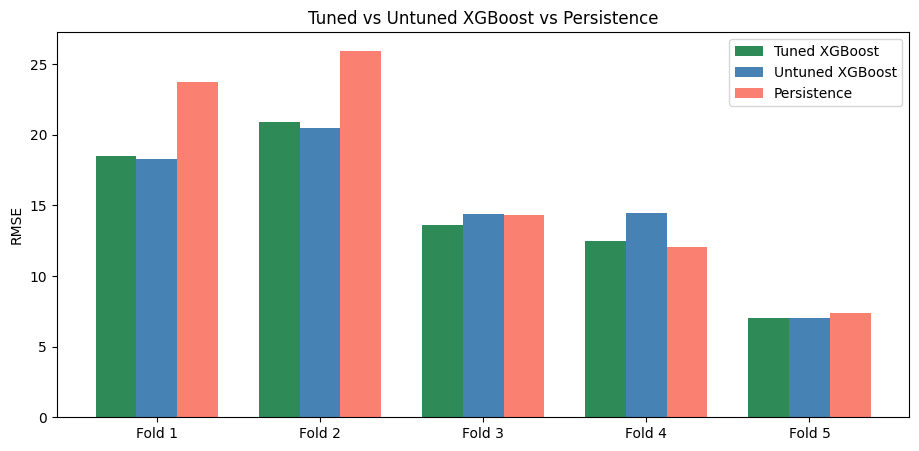

In [6]:
# RMSE per fold (all three)

x = np.arange(5)
width = 0.25

plt.figure(figsize=(11, 5))
plt.bar(x - width, final_comparison["rmse_tuned"], width, label="Tuned XGBoost", color="seagreen")
plt.bar(x, final_comparison["rmse_untuned"], width, label="Untuned XGBoost", color="steelblue")
plt.bar(x + width, final_comparison["rmse_persist"], width, label="Persistence", color="salmon")
plt.xticks(x, [f"Fold {i+1}" for i in range(5)])
plt.ylabel("RMSE")
plt.title("Tuned vs Untuned XGBoost vs Persistence")
plt.legend()
plt.show()

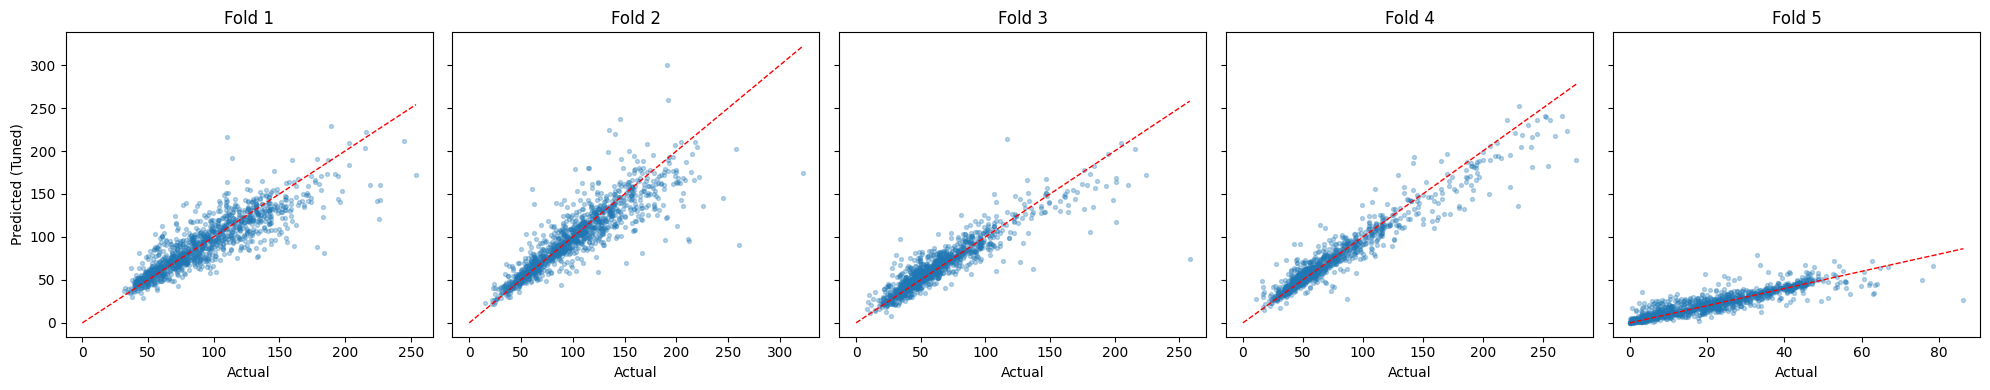

In [7]:
# Predicted vs actual, per fold (tuned model)

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

for i, fold_data in enumerate(tuned_predictions):
    ax = axes[i]
    ax.scatter(fold_data["y_actual"], fold_data["y_pred"], alpha=0.3, s=8)
    lims = [0, max(fold_data["y_actual"].max(), fold_data["y_pred"].max())]
    ax.plot(lims, lims, "r--", linewidth=1)
    ax.set_title(f"Fold {fold_data['fold']}")
    ax.set_xlabel("Actual")
    if i == 0:
        ax.set_ylabel("Predicted (Tuned)")

plt.tight_layout()
plt.show()

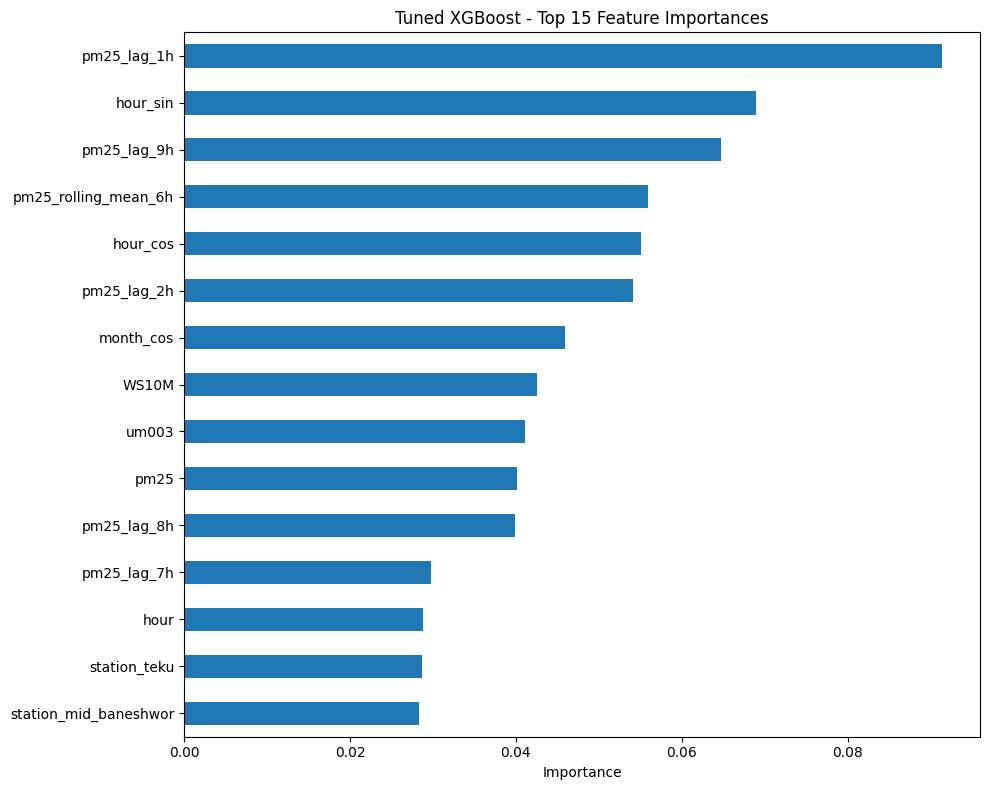

pm25_lag_1h              0.091389
hour_sin                 0.068899
pm25_lag_9h              0.064736
pm25_rolling_mean_6h     0.055888
hour_cos                 0.055137
pm25_lag_2h              0.054110
month_cos                0.045982
WS10M                    0.042608
um003                    0.041161
pm25                     0.040149
pm25_lag_8h              0.039891
pm25_lag_7h              0.029808
hour                     0.028772
station_teku             0.028657
station_mid_baneshwor    0.028318
dtype: float32


In [8]:
# Feature importance (tuned model, trained on full data)

final_tuned_model = xgb.XGBRegressor(random_state=42, n_jobs=-1, **best_params)
#final_tuned_model.fit(X, y_delta_valid)
final_tuned_model.fit(X_full, y_delta_full)       #new

importances_tuned = pd.Series(final_tuned_model.feature_importances_, index=feature_columns).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
importances_tuned.head(15).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Tuned XGBoost - Top 15 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importances_tuned.head(15))

In [9]:
# Save the tuned model and results

import os
import joblib
import json

os.makedirs("../models", exist_ok=True)

joblib.dump(final_tuned_model, "../models/xgboost_tuned_final.pkl")

tuning_summary = {
    "model": "XGBoost (tuned, delta target)",
    "validation": "Dev period (before 2026-08-01): TimeSeriesSplit (5 folds), RandomizedSearchCV (n_iter=50); hold-out: 2026-08-01 onward",
    "best_params": best_params,
    "tuned_avg_rmse": final_comparison["rmse_tuned"].mean(),
    "tuned_avg_r2": final_comparison["r2_tuned"].mean(),
    "untuned_avg_rmse": final_comparison["rmse_untuned"].mean(),
    "untuned_avg_r2": final_comparison["r2_untuned"].mean(),
    "persistence_avg_rmse": final_comparison["rmse_persist"].mean(),
    "persistence_avg_r2": final_comparison["r2_persist"].mean(),
    "holdout_rmse": rmse_hold,
    "holdout_mae": mae_hold,
    "holdout_r2": r2_hold,
    "holdout_persistence_rmse": rmse_hold_persist,
    "holdout_skill": skill_hold,
}

with open("../models/tuning_results.json", "w") as f:
    json.dump(tuning_summary, f, indent=2, default=str)

print("Saved tuned model to ../models/xgboost_tuned_final.pkl")
print("Saved results to ../models/tuning_results.json")
print(tuning_summary)

Saved tuned model to ../models/xgboost_tuned_final.pkl
Saved results to ../models/tuning_results.json
{'model': 'XGBoost (tuned, delta target)', 'validation': 'Dev period (before 2026-08-01): TimeSeriesSplit (5 folds), RandomizedSearchCV (n_iter=50); hold-out: 2026-08-01 onward', 'best_params': {'subsample': 0.6, 'reg_lambda': 1.5, 'reg_alpha': 0.1, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.6}, 'tuned_avg_rmse': np.float64(14.496979689677053), 'tuned_avg_r2': np.float64(0.8097801335625109), 'untuned_avg_rmse': np.float64(14.915006704374415), 'untuned_avg_r2': np.float64(0.803725013701864), 'persistence_avg_rmse': np.float64(16.689843529537963), 'persistence_avg_r2': np.float64(0.74472323458834), 'holdout_rmse': np.float64(6.564927835961687), 'holdout_mae': 4.2656187102639915, 'holdout_r2': 0.6356653438787934, 'holdout_persistence_rmse': np.float64(7.048489880902269), 'holdout_skill': np.float64(0.06860505627606606)}
